In [47]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import load, dump
import os
import tables
import pathlib
from IPython.display import display


from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr

### Datasets

In [48]:
corrs = load('xgb_res/correlations.joblib')

In [49]:
proteomics = load('xgb_res/proteomics_matched.joblib')

In [50]:
tables.file._open_files.close_all()
p = pathlib.Path(r"xgb_res/xgb_all_results.h5")
print("exists:", p.exists(), "size:", p.stat().st_size, "bytes")
with pd.HDFStore(str(p), mode="r") as store:
    print(store.keys())


exists: True size: 94805704 bytes
['/data']


In [51]:
# Load all data from the HDF5 file
h5_file = 'xgb_res/xgb_all_results.h5'
eps = 1e-8

with pd.HDFStore(h5_file) as store:
    keys = store.keys()
    df_list = [store[key] for key in keys]
    combined_df = pd.concat(df_list, ignore_index=True)
combined_df = combined_df.dropna(how="any").reset_index(drop=True)

# Compute absolute and squared errors
combined_df['abs_error'] = (combined_df['true'] - combined_df['predicted']).abs()
combined_df['squared_error'] = (combined_df['true'] - combined_df['predicted'])**2
combined_df['rel_error']     = combined_df['abs_error'] / (combined_df['true'].abs() + eps)
# Add overall Pearson and cosine similarity as columns
corr = combined_df['true'].corr(combined_df['predicted'])
cos  = combined_df['true'].mul(combined_df['predicted']).sum() / ((combined_df['true'].pow(2).sum()**0.5) * (combined_df['predicted'].pow(2).sum()**0.5) + eps)
combined_df['pearson_corr'] = corr
combined_df['cosine_similarity'] = cos

combined_df.head()


,protein,LOO sample,true,predicted,abs_error,squared_error,rel_error,pearson_corr,cosine_similarity
0,A2M,MDAMB468_BREAST,-0.345562,-0.691980,0.346417,0.120005,1.002474,0.655874,0.656185
1,A2M,SH4_SKIN,1.642186,0.469850,1.172336,1.374372,0.713888,0.655874,0.656185
2,A2M,AU565_BREAST,-1.129114,-0.811306,0.317809,0.101002,0.281467,0.655874,0.656185
3,A2M,KMRC1_KIDNEY,1.493333,0.888209,0.605124,0.366175,0.405217,0.655874,0.656185
4,A2M,CAL51_BREAST,0.274652,0.562785,0.288132,0.083020,1.049080,0.655874,0.656185


##  Protein-wise analysis


In [52]:
# Per-protein ranking tables: MsE, cosine similarity, Pearson correlation
def _cos_sim(a, b):
    na = np.linalg.norm(a); nb = np.linalg.norm(b)
    denom = na * nb
    return float(np.dot(a, b) / denom) if denom > 0 else np.nan

per_protein = (
    combined_df.groupby('protein', sort=False)
    .apply(lambda g: pd.Series({
        'n_samples': len(g),
        'mse': g['squared_error'].mean(),
        'cosine_similarity': _cos_sim(g['true'].to_numpy(), g['predicted'].to_numpy()),
        'pearson_corr': g['true'].corr(g['predicted'])
    }))
    .reset_index()
)

top100_mae     = per_protein.sort_values('mse', ascending=True).head(100)         # lower is better
top100_cosine  = per_protein.sort_values('cosine_similarity', ascending=False).head(100)
top100_pearson = per_protein.sort_values('pearson_corr', ascending=False).head(100)

print("Top 100 proteins by lowest MSE")
display(top100_mae)

print("\nTop 100 proteins by highest cosine similarity")
display(top100_cosine)

print("\nTop 100 proteins by highest Pearson correlation")
display(top100_pearson)


Top 100 proteins by lowest MSE


C:\Users\hp\AppData\Local\Temp\ipykernel_9004\2446286208.py:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,protein,n_samples,mse,cosine_similarity,pearson_corr
2662,PPP1CC,369.0,0.075699,0.372368,0.371856
946,DDX1,369.0,0.077811,0.328901,0.328624
2133,MIB1,369.0,0.085126,0.418951,0.418400
1627,HSPA8,369.0,0.085620,0.427174,0.421743
3797,UPF1,369.0,0.090651,0.475316,0.464729
...,...,...,...,...,...
1236,FAM98A,369.0,0.127474,0.450220,0.447847
426,BAG6,369.0,0.127665,0.422322,0.422099
699,CEP350,369.0,0.127725,0.428417,0.421063
2740,RPL23,369.0,0.127768,0.353518,0.353121



Top 100 proteins by highest cosine similarity


,protein,n_samples,mse,cosine_similarity,pearson_corr
821,CORO1A,369.0,0.545767,0.883462,0.879663
1666,IGF2BP1,369.0,0.594848,0.875025,0.871826
3864,VIM,369.0,0.618242,0.874629,0.874611
280,ARHGDIB,369.0,0.804340,0.870230,0.866663
1386,GNG12,369.0,0.595687,0.867991,0.868025
...,...,...,...,...,...
1897,LGALS1,369.0,0.761864,0.815935,0.815869
2693,PRDX2,369.0,0.611012,0.815901,0.815405
1294,FSTL1,369.0,0.970446,0.815531,0.815459
1472,H2AFY2,369.0,0.879947,0.815375,0.814682



Top 100 proteins by highest Pearson correlation


,protein,n_samples,mse,cosine_similarity,pearson_corr
821,CORO1A,369.0,0.545767,0.883462,0.879663
3864,VIM,369.0,0.618242,0.874629,0.874611
1666,IGF2BP1,369.0,0.594848,0.875025,0.871826
1386,GNG12,369.0,0.595687,0.867991,0.868025
280,ARHGDIB,369.0,0.804340,0.870230,0.866663
...,...,...,...,...,...
1161,ERAP2,369.0,0.816224,0.816246,0.815550
1294,FSTL1,369.0,0.970446,0.815531,0.815459
2693,PRDX2,369.0,0.611012,0.815901,0.815405
1472,H2AFY2,369.0,0.879947,0.815375,0.814682


In [53]:
# Intersection
set_mae  = set(top100_mae['protein'])
set_cos  = set(top100_cosine['protein'])
set_pear = set(top100_pearson['protein'])
inter_prots = sorted(set_mae & set_cos & set_pear)

print(f"Proteins in the intersection of all three top-100 lists: {len(inter_prots)}")

if len(inter_prots) == 0:
    print("No overlap across the three lists.")
else:
    # Add ranks for context
    pp_idx = per_protein.set_index('protein')
    ranked = pp_idx.assign(
        mae_rank=pp_idx['mae'].rank(method='min', ascending=True).astype(int),
        cosine_rank=pp_idx['cosine_similarity'].rank(method='min', ascending=False).astype(int),
        pearson_rank=pp_idx['pearson_corr'].rank(method='min', ascending=False).astype(int),
    )

    intersection_table = (
        ranked.loc[inter_prots, ['n_samples', 'mae', 'mae_rank',
                                 'cosine_similarity', 'cosine_rank',
                                 'pearson_corr', 'pearson_rank']]
        .sort_values(['mae', 'cosine_rank', 'pearson_rank'])
        .reset_index()
        .rename(columns={'protein': 'protein'})
    )

    display(intersection_table)

Proteins in the intersection of all three top-100 lists: 0
No overlap across the three lists.


## Error Distributions and thresholds 

c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


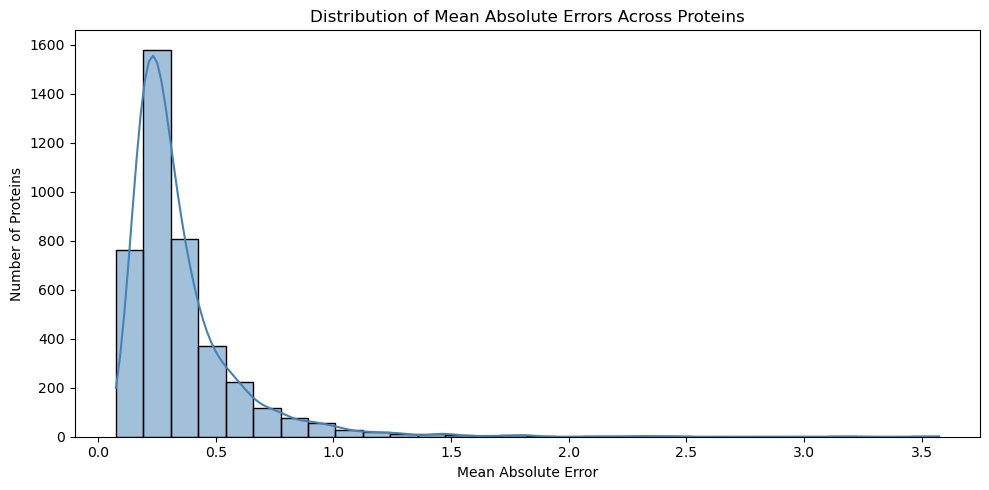

In [54]:
# 1. Compute median absolute error for each protein across samples
protein_means = combined_df.groupby("protein")["squared_error"].mean().reset_index()
protein_means.rename(columns={"squared_error": "mean_squared_error"}, inplace=True)

# 2. Plot the distribution
plt.figure(figsize=(10, 5))
sns.histplot(protein_means["mean_squared_error"], bins=30, kde=True, color="steelblue")

plt.title("Distribution of Mean Absolute Errors Across Proteins")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Number of Proteins")
plt.tight_layout()
plt.show()

Proteins with mean_squared_error < 0.1: 14


c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


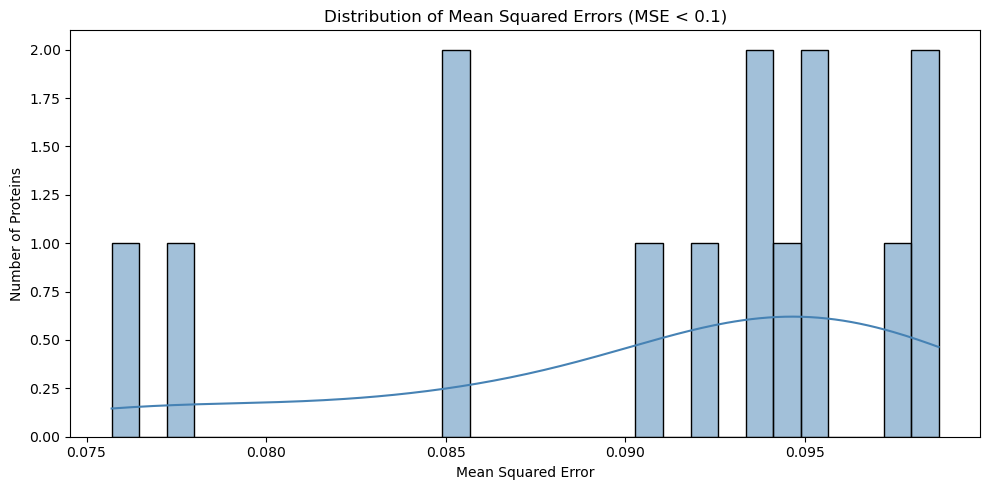

In [55]:
# MAE < 0.1
threshold = 0.1
subset = protein_means.loc[protein_means["mean_squared_error"] < threshold, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Mean Squared Errors (MSE < 0.1)")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()


Proteins with mean_squared_error < 0.2: 885


c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


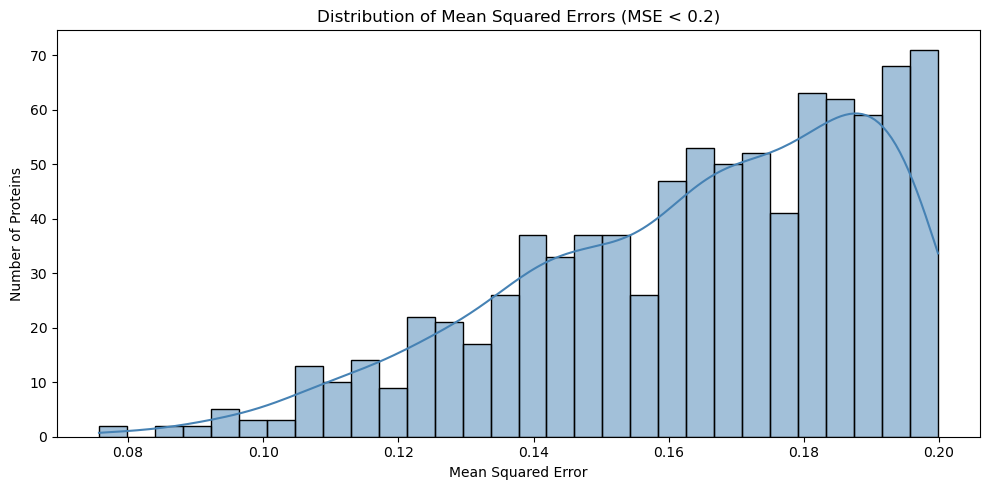

In [56]:
# Cell: MAE < 0.2
threshold = 0.2
subset = protein_means.loc[protein_means["mean_squared_error"] < threshold, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Mean Squared Errors (MSE < 0.2)")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()


Proteins with mean_squared_error < 0.3: 2257


c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


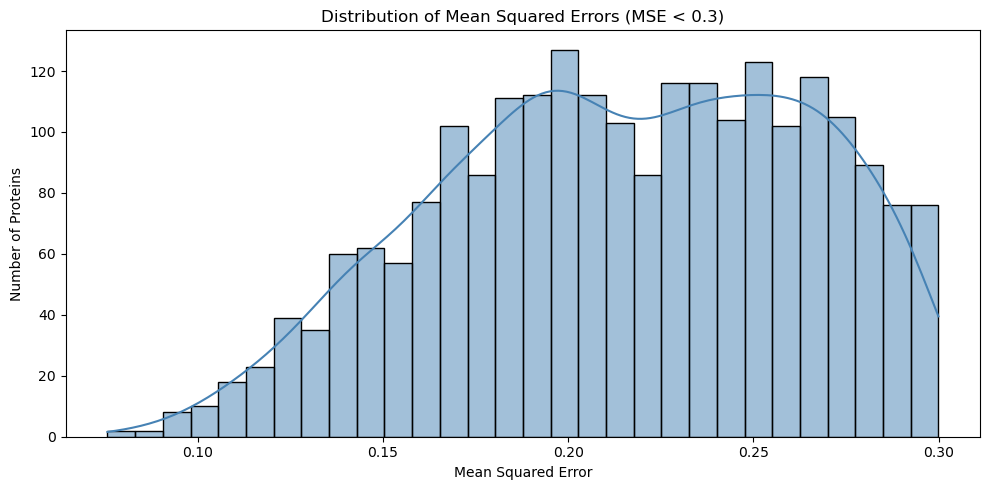

In [57]:
# Cell: MAE < 0.3
threshold = 0.3
subset = protein_means.loc[protein_means["mean_squared_error"] < threshold, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Mean Squared Errors (MSE < 0.3)")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


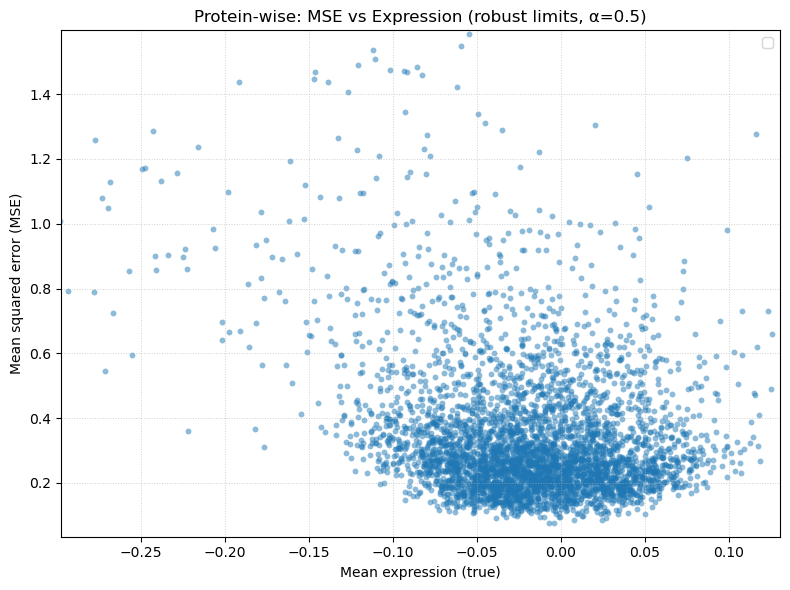

In [58]:
# MSE vs expression with robust limits and readable 1:1 line

# Recompute per-protein summary (safe if it already exists)
prot_perf = (
    combined_df.groupby('protein')
    .agg(expression=('true', 'mean'),
         mse=('squared_error', 'mean'),
         mae=('abs_error', 'mean'))
    .reset_index()
)

x = prot_perf['expression'].to_numpy()
y = prot_perf['mse'].to_numpy()

# Robust axis limits (clip to 0.5–99.5 percentiles and pad 5%)
x_lo, x_hi = np.nanpercentile(x, [0.5, 99.5])
y_lo, y_hi = np.nanpercentile(y, [0.5, 99.5])
x_pad = 0.05 * (x_hi - x_lo) if np.isfinite(x_hi - x_lo) else 1.0
y_pad = 0.05 * (y_hi - y_lo) if np.isfinite(y_hi - y_lo) else 1.0
xlim = (x_lo - x_pad, x_hi + x_pad)
ylim = (y_lo - y_pad, y_hi + y_pad)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=prot_perf, x='expression', y='mse',
    s=18, alpha=0.5, linewidth=0, edgecolor=None
)


plt.xlim(*xlim)
plt.ylim(*ylim)
plt.xlabel('Mean expression (true)')
plt.ylabel('Mean squared error (MSE)')
plt.title('Protein-wise: MSE vs Expression (robust limits, α=0.5)')
plt.grid(True, linestyle=':', linewidth=0.7, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


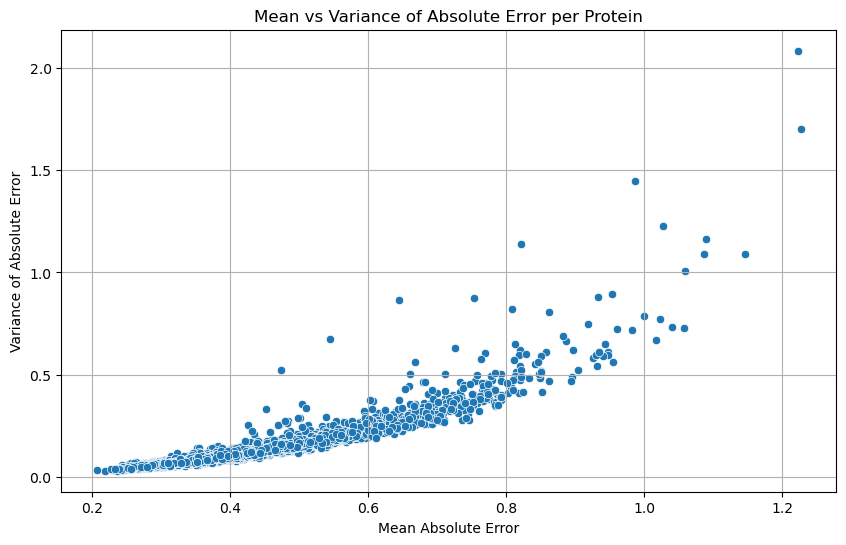

In [59]:
# Mean and variance per protein
protein_stats = combined_df.groupby('protein')['abs_error'].agg(['mean', 'var']).reset_index()

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=protein_stats, x='mean', y='var')
plt.title("Mean vs Variance of Absolute Error per Protein")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Variance of Absolute Error")
plt.grid(True)
plt.show()


#### mean error vs variance of true values

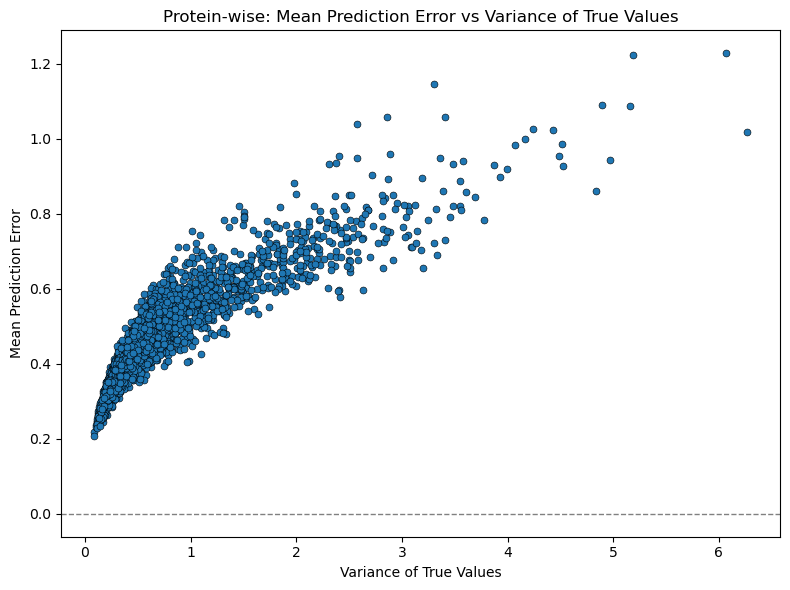

In [60]:
#Aggregate per protein 

prot_stats = (
    combined_df
    .groupby('protein')
    .agg(
        mean_error = ('abs_error', 'mean'),
        var_true   = ('true', 'var'),
    )
    .reset_index()
)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=prot_stats,
    x='var_true',
    y='mean_error',
    s=25,
    edgecolor='k'
)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Protein‑wise: Mean Prediction Error vs Variance of True Values')
plt.xlabel('Variance of True Values')
plt.ylabel('Mean Prediction Error')
plt.tight_layout()
plt.show()

### Comparison with baseline

# Samples analysis


In [61]:
protein_name = 'DYNLL1'
# Filter combined_df for that protein
protein_df = combined_df[combined_df['protein'] == protein_name]
# Sort SAMPLES by absolute error
protein_df_sorted = protein_df.sort_values(by='abs_error', ascending=True)
# Display
smallest_error = protein_df_sorted[protein_df_sorted["abs_error"]< 0.1]
smallest_error[['LOO sample', 'abs_error']]  

,LOO sample,abs_error
391104,UMUC3_URINARY_TRACT,0.002043
390820,CAL851_BREAST,0.005472
390785,HS294T_SKIN,0.005518
390841,LS513_LARGE_INTESTINE,0.005847
390928,SKMEL30_SKIN,0.006318
...,...,...
390888,MKN7_STOMACH,0.095061
390919,UACC62_SKIN,0.096895
390778,IGR37_SKIN,0.098625
390982,SW837_LARGE_INTESTINE,0.099109


In [62]:
sample_error_summary = combined_df.groupby('LOO sample').agg(
    mean_abs_error=('abs_error', 'mean'),
    std_abs_error=('abs_error', 'std'),
    mean_squared_error=('squared_error', 'mean'),
    std_squared_error=('squared_error', 'std'),
    count=('LOO sample', 'count')
).sort_values(by='mean_abs_error', ascending=False)

sample_error_summary.head()

,mean_abs_error,std_abs_error,mean_squared_error,std_squared_error,count
LOO sample,,,,,
RCHACV_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.894543,0.606449,1.167898,1.472474,4079
MOLM13_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.772734,0.597735,0.954317,1.459467,4079
IM95_STOMACH,0.707611,0.552146,0.805503,2.311568,4079
KNS42_CENTRAL_NERVOUS_SYSTEM,0.692550,0.514875,0.744656,1.120220,4079
MONOMAC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.689971,0.491175,0.717254,0.934138,4079


c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


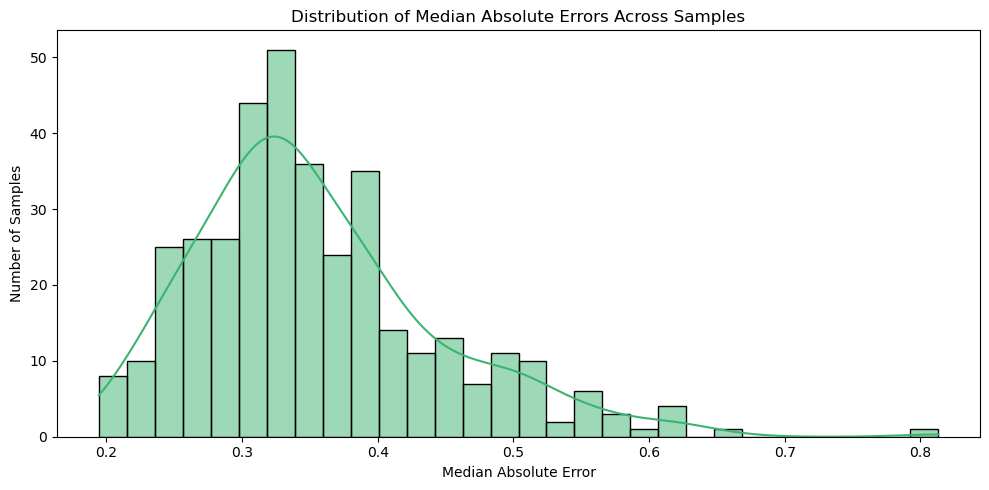

In [63]:
# Compute median absolute error across proteins for each sample
sample_medians = combined_df.groupby("LOO sample")["abs_error"].median().reset_index()
sample_medians.rename(columns={"abs_error": "median_abs_error"}, inplace=True)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(sample_medians["median_abs_error"], bins=30, kde=True, color="mediumseagreen")

plt.title("Distribution of Median Absolute Errors Across Samples")
plt.xlabel("Median Absolute Error")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


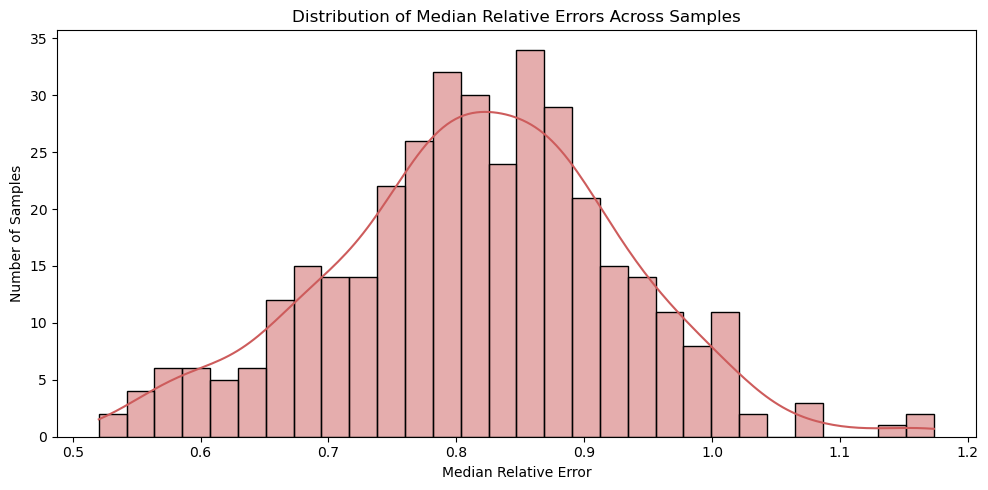

In [64]:
# Compute median relative error across proteins for each sample
sample_medians_rel = combined_df.groupby("LOO sample")["rel_error"].median().reset_index()
sample_medians_rel.rename(columns={"rel_error": "median_rel_error"}, inplace=True)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(sample_medians_rel["median_rel_error"], bins=30, kde=True, color="indianred")

plt.title("Distribution of Median Relative Errors Across Samples")
plt.xlabel("Median Relative Error")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


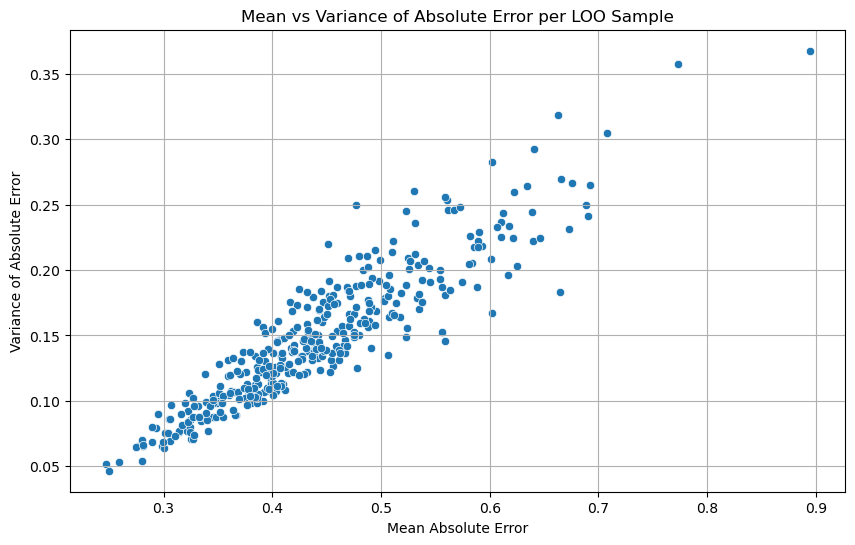

In [65]:
sample_stats = combined_df.groupby('LOO sample')['abs_error'].agg(['mean', 'var']).reset_index()

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample_stats, x='mean', y='var')
plt.title("Mean vs Variance of Absolute Error per LOO Sample")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Variance of Absolute Error")
plt.grid(True)
plt.show()


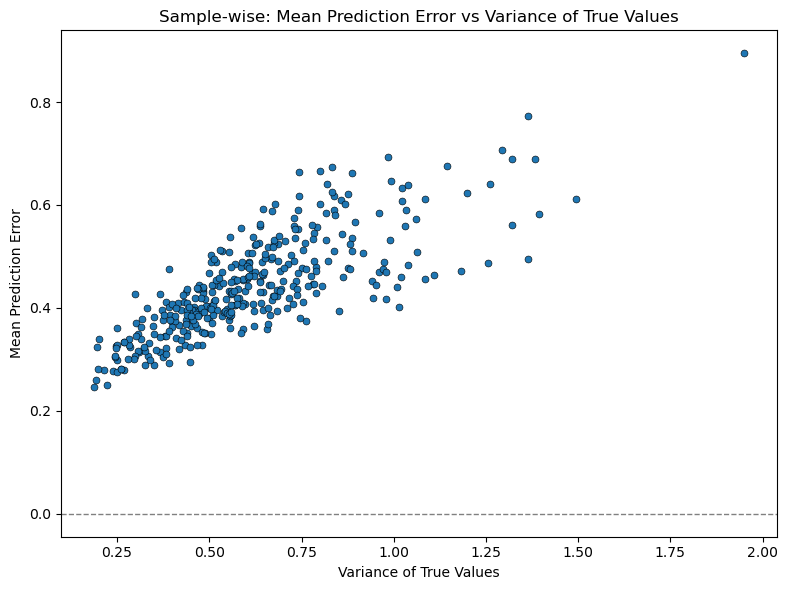

In [66]:
# Aggregate per LOO sample
sample_stats = (
    combined_df
    .groupby('LOO sample')
    .agg(
        mean_error = ('abs_error', 'mean'),
        var_true    = ('true', 'var'),
    )
    .reset_index()
)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=sample_stats,
    x='var_true',
    y='mean_error',
    s=25,
    edgecolor='k'
)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Sample‑wise: Mean Prediction Error vs Variance of True Values')
plt.xlabel('Variance of True Values')
plt.ylabel('Mean Prediction Error')
plt.tight_layout()
plt.show()

display the samples with less than 0.1 error

In [67]:
def get_less_than01(protein_name, df, error_col='abs_error', sample_col='LOO sample'):
    protein_df = df[df['protein'] == protein_name]
    sorted_df = protein_df.sort_values(by=error_col, ascending=True)
    return sorted_df[[sample_col, error_col]].query(f"{error_col} < 0.1")

small = get_less_than01('DYNLL1', combined_df)
small


,LOO sample,abs_error
391104,UMUC3_URINARY_TRACT,0.002043
390820,CAL851_BREAST,0.005472
390785,HS294T_SKIN,0.005518
390841,LS513_LARGE_INTESTINE,0.005847
390928,SKMEL30_SKIN,0.006318
...,...,...
390888,MKN7_STOMACH,0.095061
390919,UACC62_SKIN,0.096895
390778,IGR37_SKIN,0.098625
390982,SW837_LARGE_INTESTINE,0.099109


In [68]:
# Extract the tissue type from the LOO sample
small['tissue'] = small['LOO sample'].str.extract(r'_([A-Z]+)$')

# Count the occurrences of each tissue
tissue_counts = small['tissue'].value_counts()

print(tissue_counts)


tissue
LUNG           18
SKIN           15
BREAST         10
INTESTINE       9
TISSUE          8
TRACT           7
OESOPHAGUS      7
LIVER           6
ENDOMETRIUM     5
OVARY           4
SYSTEM          4
STOMACH         3
KIDNEY          3
PANCREAS        2
PLEURA          2
PROSTATE        1
THYROID         1
GANGLIA         1
BONE            1
Name: count, dtype: int64


# MAE vs Prot- Encoding Gene correlations

In [ ]:
corrs

,pearson,spearman,kendall
A2M,0.373828,0.230195,0.157938
AAAS,0.033262,0.054040,0.037045
AACS,0.475468,0.446383,0.309187
AAGAB,0.345481,0.402540,0.279094
AAK1,0.623951,0.585448,0.414043
...,...,...,...
ZWINT,0.287495,0.285369,0.193985
ZYG11B,0.327869,0.335152,0.227918
ZYX,0.685739,0.657462,0.478076
ZZEF1,0.343196,0.383925,0.260961


In [ ]:
sorted(protein_error_summary.index)

['A2M',
 'AAAS',
 'AACS',
 'AAGAB',
 'AAK1',
 'AAMDC',
 'AAMP',
 'AAR2',
 'AARS',
 'AARS2',
 'AARSD1',
 'AASDHPPT',
 'AASS',
 'AATF',
 'ABCB10',
 'ABCB6',
 'ABCB7',
 'ABCB8',
 'ABCC1',
 'ABCC4',
 'ABCD1',
 'ABCD3',
 'ABCE1',
 'ABCF1',
 'ABCF2',
 'ABCF3',
 'ABHD10',
 'ABHD11',
 'ABHD12',
 'ABHD14B',
 'ABHD16A',
 'ABI1',
 'ABI2',
 'ABLIM1',
 'ABT1',
 'ACAA1',
 'ACAA2',
 'ACACA',
 'ACAD10',
 'ACAD8',
 'ACAD9',
 'ACADM',
 'ACADS',
 'ACADSB',
 'ACADVL',
 'ACAP2',
 'ACAT1',
 'ACAT2',
 'ACBD3',
 'ACBD5',
 'ACBD6',
 'ACIN1',
 'ACLY',
 'ACO1',
 'ACO2',
 'ACOT13',
 'ACOT2',
 'ACOT7',
 'ACOT8',
 'ACOT9',
 'ACOX1',
 'ACP1',
 'ACP2',
 'ACP6',
 'ACSF2',
 'ACSF3',
 'ACSL1',
 'ACSL3',
 'ACSL4',
 'ACSL5',
 'ACSS2',
 'ACTA2',
 'ACTB',
 'ACTL6A',
 'ACTL8',
 'ACTN1',
 'ACTN4',
 'ACTR10',
 'ACTR1A',
 'ACTR2',
 'ACTR3',
 'ACTR5',
 'ACY1',
 'ACYP1',
 'ACYP2',
 'ADA',
 'ADAM10',
 'ADAM15',
 'ADAM17',
 'ADAM9',
 'ADAR',
 'ADCK3',
 'ADCK4',
 'ADD1',
 'ADD3',
 'ADH5',
 'ADI1',
 'ADIRF',
 'ADK',
 'ADNP',
 'ADO',


In [ ]:
corrs = corrs.reindex(protein_error_summary.index)
corrs

,pearson,spearman,kendall
protein,,,
IGF2BP1,0.910633,0.831373,0.638656
BASP1,0.907582,0.882568,0.685089
MAGEA4,0.899245,0.470281,0.335682
GDA,0.861059,0.680194,0.501851
MAP1B,0.892199,0.894819,0.706390
...,...,...,...
MRPS30,0.029631,0.030751,0.020991
OTUB1,0.372115,0.394512,0.272672
CNOT11,0.192063,0.179745,0.122058


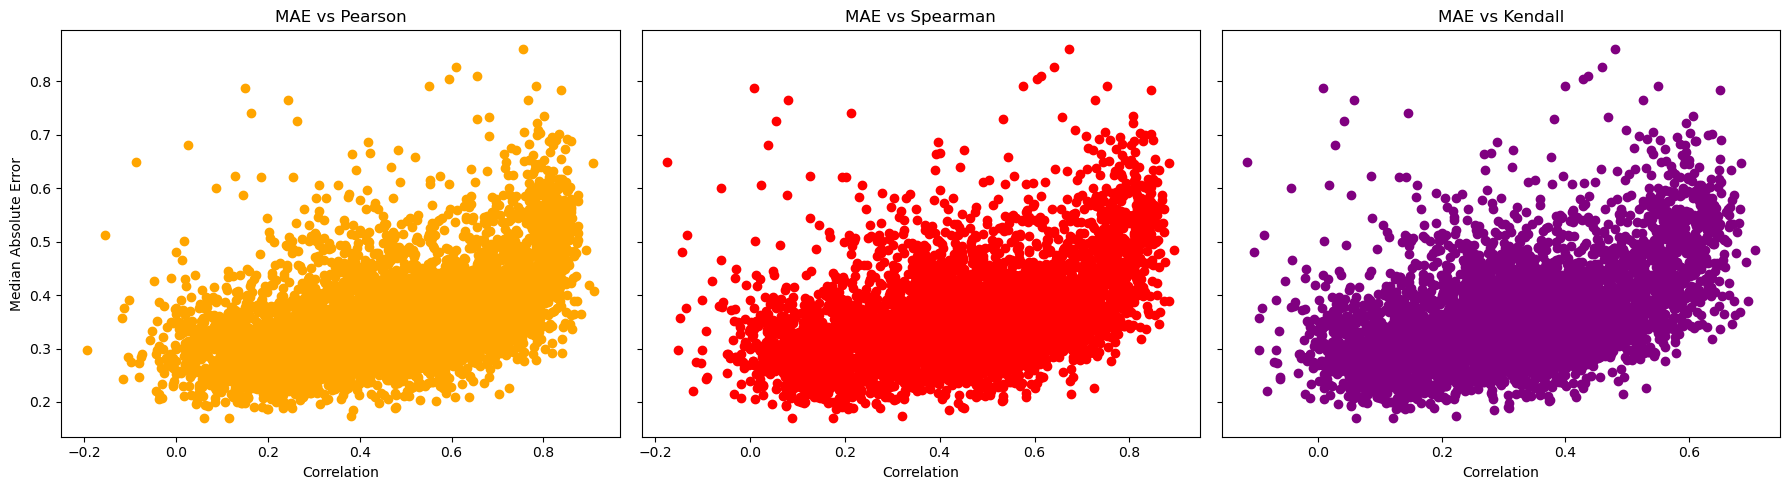

In [ ]:

mae = protein_error_summary['median_abs_error']

# Define custom colors for each correlation type
colors = ['orange', 'red', 'purple']  # Feel free to change these

# Create subplots: 1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Plot each correlation type separately
for ax, col, color in zip(axes, corrs.columns, colors):
    ax.scatter(corrs[col], mae, color=color)
    ax.set_title(f'MAE vs {col.capitalize()}')
    ax.set_xlabel('Correlation')
    ax.grid(False)

# Common Y label
axes[0].set_ylabel('Median Absolute Error')

plt.tight_layout()
plt.show()

